# 03 · Vintages exactos de ALFRED (bloque 3)

Este notebook recorre lo que cambia en la base de series con el **bloque 3**: las 161 series revisables de FRED
(empleo, precios, PIB, crédito, índices de condiciones financieras...) ya no se cargan con el último dato de hoy,
sino con **todas sus vintages de ALFRED**. Cada fila es un valor nuevo o revisado, con `vintage` = el día en que
ALFRED lo registró y `fecha_publicacion` = la primera decisión (16:30 de Nueva York) tras la hora de su release.
`get_serie(id, fecha)` devuelve así el dato **tal como se conocía** en `fecha`.

La base vive fuera del repositorio (`<corpus>/mercados_series/series/base_series.parquet`, términos de FRED). Con
`EJECUTAR = False` el notebook solo la lee; para reconstruirla: `python -m ingesta.mercados_series descargar-alfred`
(por tandas), `descargar-fred-vivo` y `construir-base --sin-red --desde-cero`.

Las salidas **no muestran tablas de valores** de las series (licencias): solo recuentos, fechas, porcentajes de
revisión y gráficos.

Secciones:

1. Qué se ha bajado: series por grupo, primer vintage y número de vintages.
2. Mapa de calor de las revisiones de PAYEMS (2007-2010).
3. El empleo de 2008: primera estimación frente al dato revisado de hoy.
4. Cuánto se revisan las series: distribución por grupo.
5. Cierres del gobierno: retraso de publicación en 2013, 2018-19 y 2025.
6. Cuánto filtraba el lag fijo del bloque 2.
7. Índices re-estimados enteros: la misma semana del NFCI en distintos vintages.
8. Ediciones académicas: cuántos valores cambian entre ediciones (French, Shiller, Goyal-Welch).
9. Conclusiones.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

from ingesta.comun.rutas import resultados_dir
from ingesta.mercados_series import almacen, base, tools
from ingesta.mercados_series import catalogo as cat_mod
from ingesta.mercados_series.fuentes import alfred

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)

EJECUTAR = False   # True: reconstruye la base sin red (crudos de ALFRED y FRED ya descargados) antes de leerla
RUTA = almacen.ruta_series()
if EJECUTAR:
    resumen, _ = base.construir_base(sin_red=True, desde_cero=True, registro=print)
if not RUTA.exists():
    raise FileNotFoundError(f'No hay base en {RUTA}: python -m ingesta.mercados_series construir-base --sin-red '
                            '--desde-cero (o EJECUTAR = True)')

CAT = cat_mod.cargar_catalogo()
IDS = alfred.ids_alfred(CAT)
TABLAS = resultados_dir('mercados_series') / 'tablas'
REV = pd.read_csv(TABLAS / 'alfred_revisiones_resumen.csv')
LAG = pd.read_csv(TABLAS / 'alfred_vs_lag.csv')
COB = pd.read_csv(TABLAS / 'cobertura_series.csv')
GRUPOS = sorted(REV['grupo'].dropna().unique())
PALETA = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#7b5bd6', '#c0392b', '#17becf',
          '#8a8984', '#5d4037', '#b5a000']
COLOR_GRUPO = dict(zip(GRUPOS, PALETA))
print(f'{RUTA}: {COB["n_obs"].sum():,} periodos con valor en {len(COB)} series; '
      f'{len(IDS)} series de ALFRED (vintage_exacto)')

D:\tfm_corpus\mercados_series\series\base_series.parquet: 2,492,785 periodos con valor en 1434 series; 161 series de ALFRED (vintage_exacto)


## 1. Qué se ha bajado

Las 161 series de la lista aprobada (`tablas/alfred_lista_propuesta.csv`), agrupadas por tema. ALFRED empezó a
guardar vintages en momentos muy distintos: el empleo y el IPC tienen vintages desde los años cincuenta-setenta,
mientras que muchos índices regionales o de condiciones financieras solo desde 2011-2021. Todo lo anterior al primer
vintage se carga con el valor de ese primer vintage y la fecha de la regla previa (`lag_fijo`, aviso «anterior a
ALFRED»).

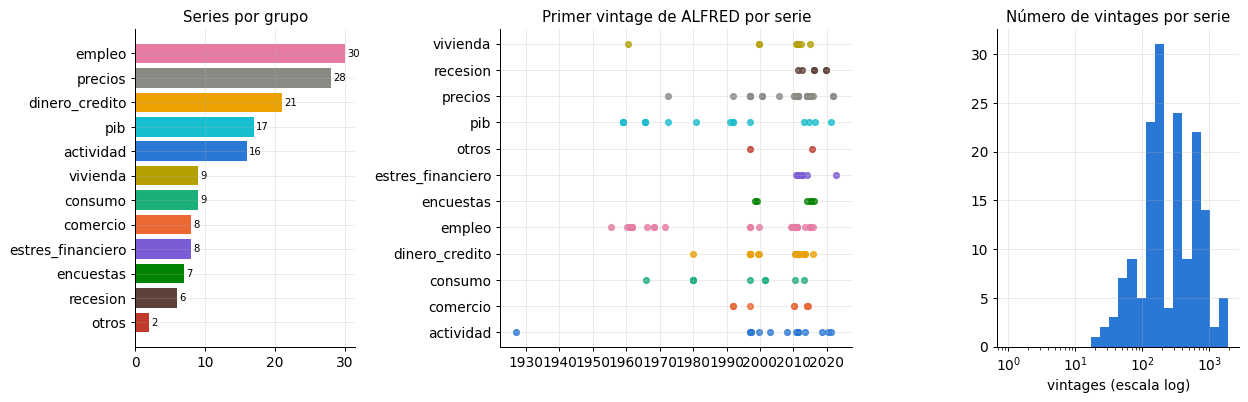

Series por década de su primer vintage: 1920s: 1, 1950s: 5, 1960s: 14, 1970s: 6, 1980s: 2, 1990s: 35, 2000s: 9, 2010s: 83, 2020s: 6
Vintages por serie: mediana 205, máximo 1931 (fred:M2SL); filas anteriores a ALFRED: 74,621 en 156 series
Re-estimadas enteras: 16; con unidad por vintage: 26; vintages en la base (las 161): 135,496


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.6, 1.1]})
n = REV['grupo'].value_counts().sort_values()
axes[0].barh(n.index, n.values, color=[COLOR_GRUPO[g] for g in n.index])
axes[0].set_title('Series por grupo')
for i, v in enumerate(n.values):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=8)

r = REV.assign(primer=pd.to_datetime(REV['primer_vintage'])).sort_values('primer')
for g, d in r.groupby('grupo'):
    axes[1].scatter(d['primer'], [GRUPOS.index(g)] * len(d), color=COLOR_GRUPO[g], s=22, alpha=0.8)
axes[1].set_yticks(range(len(GRUPOS)))
axes[1].set_yticklabels(GRUPOS)
axes[1].set_title('Primer vintage de ALFRED por serie')
axes[1].xaxis.set_major_locator(mdates.YearLocator(10))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[2].hist(REV['n_vintages'], bins=np.logspace(0, np.log10(REV['n_vintages'].max() + 1), 25), color='#2a78d6')
axes[2].set_xscale('log')
axes[2].set_title('Número de vintages por serie')
axes[2].set_xlabel('vintages (escala log)')
plt.tight_layout()
plt.show()

dec = (r['primer'].dt.year // 10 * 10).value_counts().sort_index()
print('Series por década de su primer vintage:', ', '.join(f'{d}s: {k}' for d, k in dec.items()))
print(f'Vintages por serie: mediana {REV["n_vintages"].median():.0f}, máximo {REV["n_vintages"].max()} '
      f'({REV.loc[REV["n_vintages"].idxmax(), "serie"]}); filas anteriores a ALFRED: '
      f'{REV["n_previas_alfred"].sum():,} en {int((REV["n_previas_alfred"] > 0).sum())} series')
filas = COB.set_index('id').loc[IDS]
print(f'Re-estimadas enteras: {int(REV["reestimada"].sum())}; con unidad por vintage: '
      f'{int(REV["unidad_por_vintage"].sum())}; vintages en la base (las 161): {filas["n_vintages"].sum():,}')

## 2. Mapa de calor de las revisiones de PAYEMS (2007-2010)

Cada fila es un mes de referencia y cada columna un vintage (los del periodo 2007-2012 más el de hoy). El color es la
diferencia entre el valor de ese mes en ese vintage y su **primera estimación**, en miles de empleos. Se ven las dos
revisiones habituales de los meses siguientes y las revisiones de referencia anuales (benchmark de febrero), que
en la crisis de 2008-2009 restaron cientos de miles de empleos.

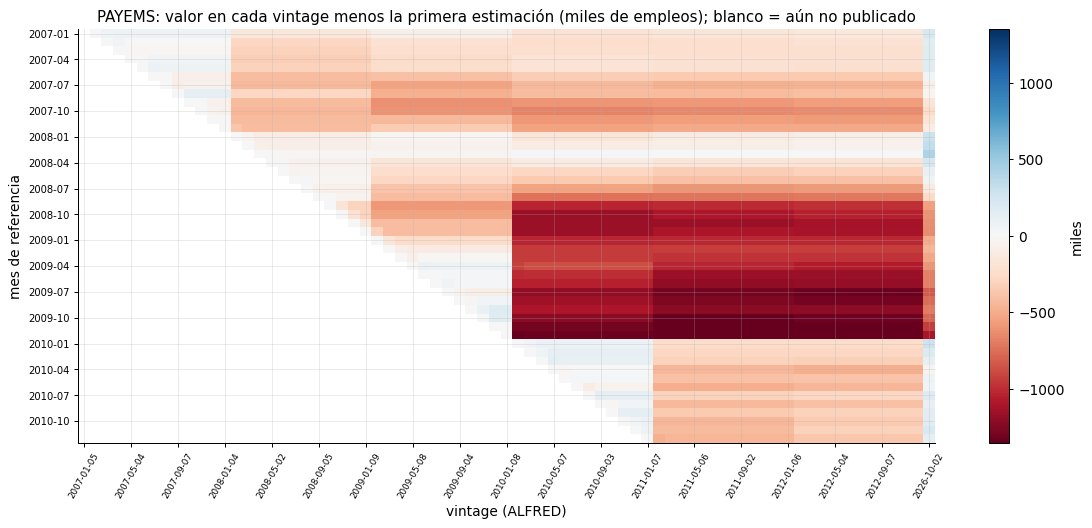

73 vintages; meses de 2007-2010 revisados a la baja respecto a su primera estimación: 52% (magnitudes, solo en el gráfico)


In [3]:
pay = almacen.leer_series('fred:PAYEMS')
pay = pay[pay['valor'].notna()]
meses = pd.date_range('2007-01-01', '2010-12-01', freq='MS')
vint = sorted(v for v in pay.loc[pay['metodo_publicacion'] == 'vintage_exacto', 'vintage'].unique()
              if '2007-01-01' <= v <= '2012-12-31')
vint.append(pay['vintage'].max())
mat = pd.DataFrame({v: alfred.vista_vintage(pay, 'fred:PAYEMS', v).reindex(meses) for v in vint})
primera = alfred.primeras_y_ultimas(pay).set_index('fecha_referencia')['primer_valor'].reindex(meses)
dif = mat.sub(primera, axis=0)
fig, ax = plt.subplots(figsize=(13, 6))
lim = np.nanpercentile(np.abs(dif.to_numpy()), 98)
im = ax.imshow(dif.to_numpy(), aspect='auto', cmap='RdBu', vmin=-lim, vmax=lim, interpolation='nearest')
ax.set_yticks(range(0, len(meses), 3))
ax.set_yticklabels([m.strftime('%Y-%m') for m in meses[::3]], fontsize=8)
paso = max(1, len(vint) // 18)
ax.set_xticks(range(0, len(vint), paso))
ax.set_xticklabels(vint[::paso], rotation=60, fontsize=7)
ax.set_xlabel('vintage (ALFRED)')
ax.set_ylabel('mes de referencia')
ax.set_title('PAYEMS: valor en cada vintage menos la primera estimación (miles de empleos); blanco = aún no publicado')
plt.colorbar(im, ax=ax, label='miles')
plt.tight_layout()
plt.show()
rev = dif.iloc[:, -1]
print(f'{len(vint)} vintages; meses de 2007-2010 revisados a la baja respecto a su primera estimación: '
      f'{(rev < 0).mean():.0%} (magnitudes, solo en el gráfico)')

## 3. El empleo de 2008: primera estimación frente al dato de hoy

La variación mensual del empleo no agrícola (miles de empleos) tal como se publicó por primera vez cada mes de 2008
(diferencia con el mes anterior **dentro del mismo vintage**) frente a la variación que da la serie revisada de hoy.
Un agente que decidiera en 2008 veía las barras claras, no las oscuras.

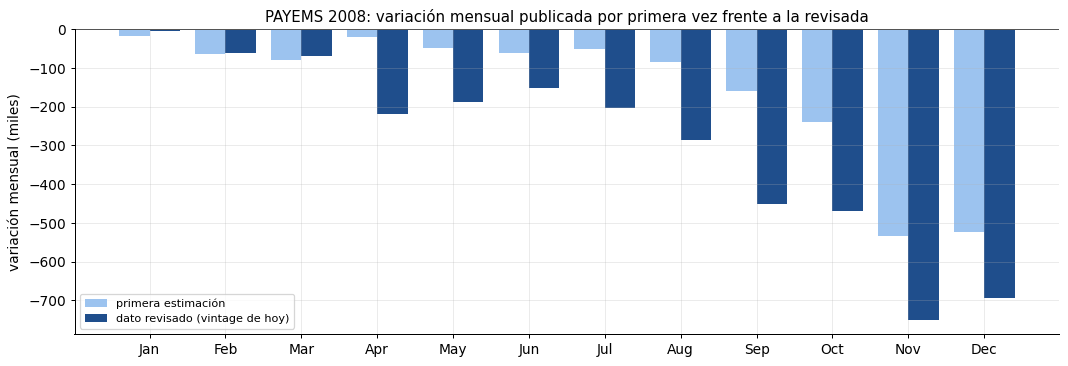

2008: la caída revisada es 1.9 veces la de la primera estimación; meses con más caída en el dato revisado: 9 de 12. Fechas de la primera publicación: 2008-02-01 a 2009-01-09
get_serie('PAYEMS', '2008-12-10'): último periodo 2008-11-01, publicado 2008-12-05, vintage 2008-12-05, método vintage_exacto, avisos: []


In [4]:
def cambio_primera(df, sid, mes):
    fila = df[(df['fecha_referencia'] == mes) & df['valor'].notna()].sort_values('fecha_publicacion').iloc[0]
    vista = alfred.vista_vintage(df, sid, fila['vintage'])
    return vista.loc[mes] - vista.loc[mes - pd.offsets.MonthBegin(1)], fila['fecha_publicacion']

m2008 = pd.date_range('2008-01-01', '2008-12-01', freq='MS')
hoy = alfred.vista_vintage(pay, 'fred:PAYEMS', pay['vintage'].max())
primeras = [cambio_primera(pay, 'fred:PAYEMS', m) for m in m2008]
pc = pd.Series([p[0] for p in primeras], index=m2008)
actual = hoy.diff().reindex(m2008)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(m2008))
ax.bar(x - 0.2, pc.values, 0.4, color='#9cc3ef', label='primera estimación')
ax.bar(x + 0.2, actual.values, 0.4, color='#1f4e8c', label='dato revisado (vintage de hoy)')
ax.axhline(0, color='#555', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([m.strftime('%b') for m in m2008])
ax.set_ylabel('variación mensual (miles)')
ax.set_title('PAYEMS 2008: variación mensual publicada por primera vez frente a la revisada')
ax.legend()
plt.tight_layout()
plt.show()
print(f'2008: la caída revisada es {actual.sum() / pc.sum():.1f} veces la de la primera estimación; '
      f'meses con más caída en el dato revisado: {(actual < pc).sum()} de 12. Fechas de la primera publicación: '
      f'{min(p[1] for p in primeras).date()} a {max(p[1] for p in primeras).date()}')
r = tools.get_serie('PAYEMS', '2008-12-10')
u = r.ultimo()
print(f"get_serie('PAYEMS', '2008-12-10'): último periodo {u['fecha_referencia']}, publicado {u['fecha_publicacion']}, "
      f"vintage {u['vintage']}, método {u['metodo_publicacion']}, avisos: {r.avisos}")

## 4. Cuánto se revisan las series

Para cada periodo con primera publicación real (posterior al primer vintage), la revisión total es
`|último − primero| / |primero|` en %. Cada punto del diagrama es la **mediana** de una serie; las cajas resumen
cada grupo. Las series con unidad por vintage (cambios de año base, dólares encadenados) y las re-estimadas enteras
se marcan aparte: su % incluye el cambio de base o la re-estimación, no solo la revisión del dato. Las series con
revisión mediana nula (indicadores 0/1 de recesión, algunas encuestas) se dibujan en el borde izquierdo; en las
tasas cercanas a cero (crecimiento del PIB, índices centrados en cero) el % se dispara aunque la revisión en puntos
sea pequeña.

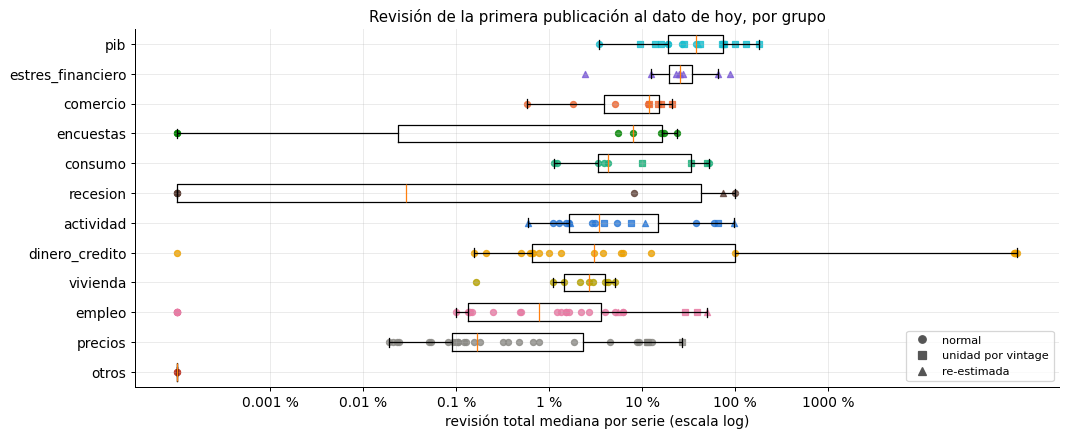

Series medidas: 161; % de periodos revisados (mediana por serie): 99 %; revisión mediana de las normales: 1.33 %
Grupos por revisión mediana: otros 0.00 %, precios 0.17 %, empleo 0.86 %, vivienda 2.69 %, dinero_credito 3.06 %, actividad 3.48 %, recesion 4.05 %, consumo 4.30 %, encuestas 8.06 %, comercio 11.79 %, estres_financiero 25.31 %, pib 37.50 %


In [5]:
d = REV.dropna(subset=['revision_pct_mediana']).copy()
d['tipo'] = np.where(d['reestimada'], 're-estimada', np.where(d['unidad_por_vintage'], 'unidad por vintage', 'normal'))
orden = d.groupby('grupo')['revision_pct_mediana'].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
datos = [np.log10(d.loc[d['grupo'] == g, 'revision_pct_mediana'].clip(lower=1e-4)) for g in orden]
ax.boxplot(datos, vert=False, widths=0.6, showfliers=False)
marcas = {'normal': 'o', 'unidad por vintage': 's', 're-estimada': '^'}
for i, g in enumerate(orden, start=1):
    for t, m in marcas.items():
        sel = d[(d['grupo'] == g) & (d['tipo'] == t)]
        ax.scatter(np.log10(sel['revision_pct_mediana'].clip(lower=1e-4)), np.full(len(sel), i), marker=m, s=24,
                   color=COLOR_GRUPO[g], alpha=0.8, label=t if i == 1 else None)
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden)
ticks = [-3, -2, -1, 0, 1, 2, 3]
ax.set_xticks(ticks)
ax.set_xticklabels([f'{10 ** t:g} %' for t in ticks])
ax.set_xlabel('revisión total mediana por serie (escala log)')
ax.set_title('Revisión de la primera publicación al dato de hoy, por grupo')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], marker=m, color='#555', ls='', label=t) for t, m in marcas.items()], loc='lower right')
plt.tight_layout()
plt.show()
normal = d[d['tipo'] == 'normal']
print(f'Series medidas: {len(d)}; % de periodos revisados (mediana por serie): {d["pct_revisados"].median():.0f} %; '
      f'revisión mediana de las normales: {normal["revision_pct_mediana"].median():.2f} %')
print('Grupos por revisión mediana:', ', '.join(f'{g} {d.loc[d["grupo"] == g, "revision_pct_mediana"].median():.2f} %'
                                             for g in orden))

## 5. Cierres del gobierno: retraso de publicación

Días naturales desde el fin del periodo de referencia hasta la **primera publicación real** en ALFRED, mes a mes,
alrededor de los tres cierres recientes: octubre de 2013 (BLS, Census y BEA), diciembre 2018 - enero 2019 (Census y
BEA; el BLS tenía presupuesto) y octubre-noviembre de 2025 (BLS; el IPC de octubre no se publicó nunca). Las
bandas grises son los días de cierre. Una regla de lag fijo no ve ninguno de estos saltos.

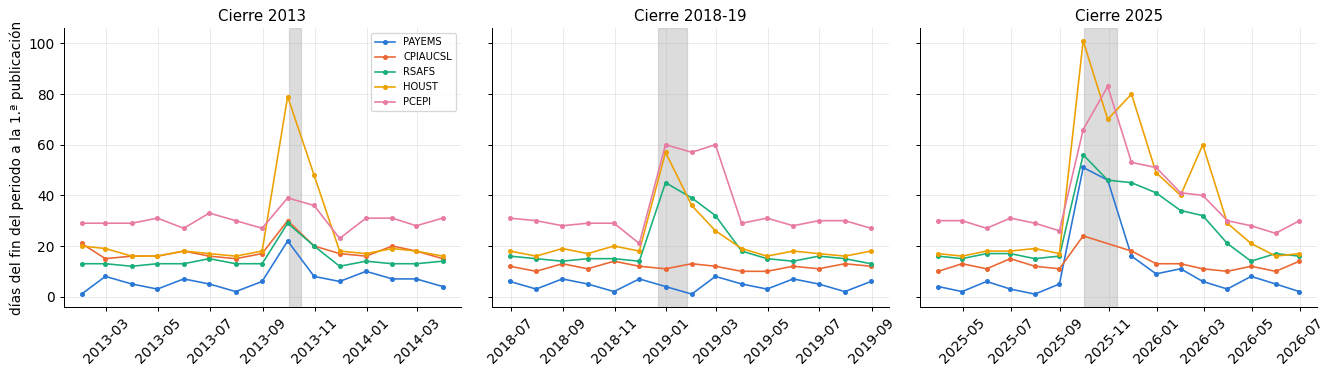

fred:PAYEMS | 1.ª publicación: 2013-09 → 2013-10-22, 2018-11 → 2018-12-07, 2025-09 → 2025-11-20
fred:CPIAUCSL | 1.ª publicación: 2013-09 → 2013-10-30, 2018-11 → 2018-12-12, 2025-09 → 2025-10-24
fred:RSAFS | 1.ª publicación: 2013-09 → 2013-10-29, 2018-11 → 2018-12-14, 2025-09 → 2025-11-25
get_serie('CPIAUCSL', '2026-01-15'), aviso del hueco: ["2025-10-01: valor nulo (hueco declarado): ALFRED sin valor ('.') en este vintage: dato no publicado (hueco de la fuente)"]


In [6]:
SERIES_CIERRE = ['fred:PAYEMS', 'fred:CPIAUCSL', 'fred:RSAFS', 'fred:HOUST', 'fred:PCEPI']
cierre = almacen.leer_series(SERIES_CIERRE)
pu = alfred.primeras_y_ultimas(cierre)
pu = pu[pu['primer_metodo'] == 'vintage_exacto']
pu['fin'] = pu['fecha_referencia'] + pd.offsets.MonthEnd(0)
pu['retraso'] = (pu['primera_publicacion'] - pu['fin']).dt.days
EPISODIOS = [('2013', '2013-01-01', '2014-03-01', [('2013-10-01', '2013-10-16')]),
             ('2018-19', '2018-06-01', '2019-08-01', [('2018-12-22', '2019-01-25')]),
             ('2025', '2025-03-01', '2026-06-01', [('2025-10-01', '2025-11-12')])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, (nombre, ini, fin, cierres) in zip(axes, EPISODIOS):
    for i, sid in enumerate(SERIES_CIERRE):
        g = pu[(pu['serie'] == sid) & pu['fecha_referencia'].between(ini, fin)]
        ax.plot(g['fin'], g['retraso'], marker='o', ms=3, lw=1.3, color=PALETA[i], label=sid.split(':')[1])
    for a, b in cierres:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='#bbb', alpha=0.5)
    ax.set_title(f'Cierre {nombre}')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('días del fin del periodo a la 1.ª publicación')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for sid in ('fred:PAYEMS', 'fred:CPIAUCSL', 'fred:RSAFS'):
    g = pu[pu['serie'] == sid].set_index('fecha_referencia')['primera_publicacion']
    sel = {k: g.get(pd.Timestamp(k)) for k in ('2013-09-01', '2018-11-01', '2025-09-01')}
    print(sid, '| 1.ª publicación:', ', '.join(f'{k[:7]} → {v.date() if v is not None else "—"}' for k, v in sel.items()))
cpi = tools.get_serie('CPIAUCSL', '2026-01-15')
print("get_serie('CPIAUCSL', '2026-01-15'), aviso del hueco:", [a for a in cpi.avisos if '2025-10' in a])

## 6. Cuánto filtraba el lag fijo del bloque 2

En el bloque 2 estas series se cargaban con el **último vintage** y una fecha por regla (`lag_fijo`, la regla
previa del catálogo). `fuentes.alfred.comparar_con_lag` compara esa regla con la primera publicación real de cada
periodo posterior al primer vintage (sin los «rellenos de historia»: periodos antiguos que ALFRED añadió más tarde,
como USREC de 1854-1920): si la regla da una fecha anterior, el dato se veía **antes** de existir.
Además, todos los valores eran los revisados de hoy. Con los vintages exactos (bloque 3) ambos adelantos son cero
por construcción (`adelantos_bloque3`).

156 series con regla previa; 48,161 periodos medidos; la regla adelantaba 1,371 (2.8 %); series con algún adelanto: 128; adelanto máximo 144 días (fred:MSPUS); rellenos de historia excluidos: 4,419


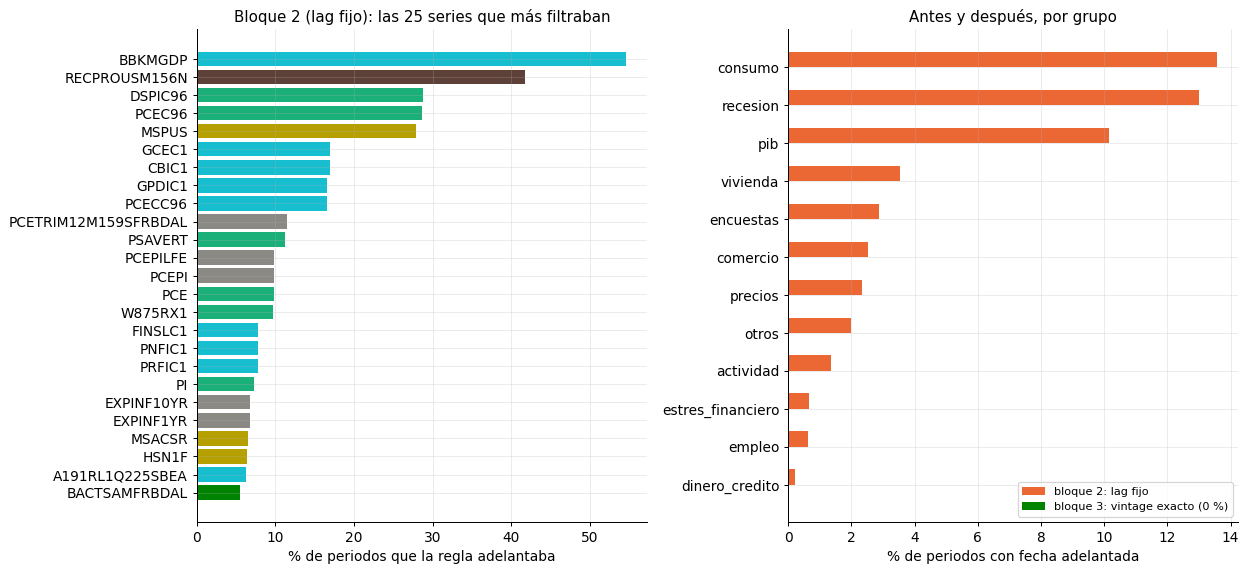

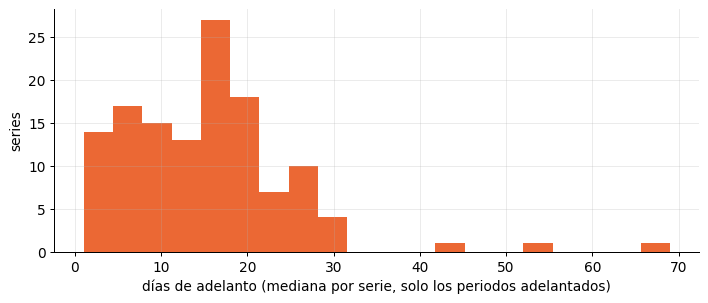

La regla también retrasa: mediana por serie de 18 días en los periodos retrasados (conservadora, salvo en cierres del gobierno y calendarios irregulares).


In [7]:
L = LAG.copy()
L['dias_adelanta_mediana'] = L['dias_adelanta_mediana'].where(L['n_adelanta'] > 0)
tot = L[['n_periodos', 'n_adelanta']].sum()
print(f'{len(L)} series con regla previa; {int(tot.n_periodos):,} periodos medidos; la regla adelantaba '
      f'{int(tot.n_adelanta):,} ({100 * tot.n_adelanta / tot.n_periodos:.1f} %); series con algún adelanto: '
      f'{int((L["n_adelanta"] > 0).sum())}; adelanto máximo {int(L["dias_adelanta_max"].max())} días '
      f'({L.loc[L["dias_adelanta_max"].idxmax(), "serie"]}); rellenos de historia excluidos: {int(L["n_relleno"].sum()):,}')
top = L[L['n_adelanta'] > 0].sort_values('pct_adelanta', ascending=False).head(25)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(top['serie'].str.split(':').str[1][::-1], top['pct_adelanta'][::-1],
             color=[COLOR_GRUPO.get(g, '#888') for g in top['grupo'][::-1]])
axes[0].set_xlabel('% de periodos que la regla adelantaba')
axes[0].set_title('Bloque 2 (lag fijo): las 25 series que más filtraban')
por_grupo = L.groupby('grupo')[['n_periodos', 'n_adelanta']].sum()
por_grupo['antes'] = 100 * por_grupo['n_adelanta'] / por_grupo['n_periodos']
por_grupo = por_grupo.sort_values('antes')
y = np.arange(len(por_grupo))
axes[1].barh(y + 0.2, por_grupo['antes'], 0.4, color='#eb6834', label='bloque 2: lag fijo')
axes[1].barh(y - 0.2, np.zeros(len(por_grupo)), 0.4, color='#008300', label='bloque 3: vintage exacto (0 %)')
axes[1].set_yticks(y)
axes[1].set_yticklabels(por_grupo.index)
axes[1].set_xlabel('% de periodos con fecha adelantada')
axes[1].set_title('Antes y después, por grupo')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(L['dias_adelanta_mediana'].dropna(), bins=20, color='#eb6834')
ax.set_xlabel('días de adelanto (mediana por serie, solo los periodos adelantados)')
ax.set_ylabel('series')
plt.tight_layout()
plt.show()
print(f'La regla también retrasa: mediana por serie de {L["dias_retrasa_mediana"].median():.0f} días en los '
      f'periodos retrasados (conservadora, salvo en cierres del gobierno y calendarios irregulares).')

## 7. Índices re-estimados enteros: el NFCI

El NFCI de la Fed de Chicago se re-estima **entero** cada semana: cada vintage cambia toda la historia. Arriba, la
semana de la quiebra de Lehman (2008-09-19) en cada vintage desde el primero (2011-05-25); abajo, el tramo 2007-2010
tal como lo veía un agente en cuatro fechas. `get_serie` avisa de que los valores pasados cambian con la fecha de
consulta.

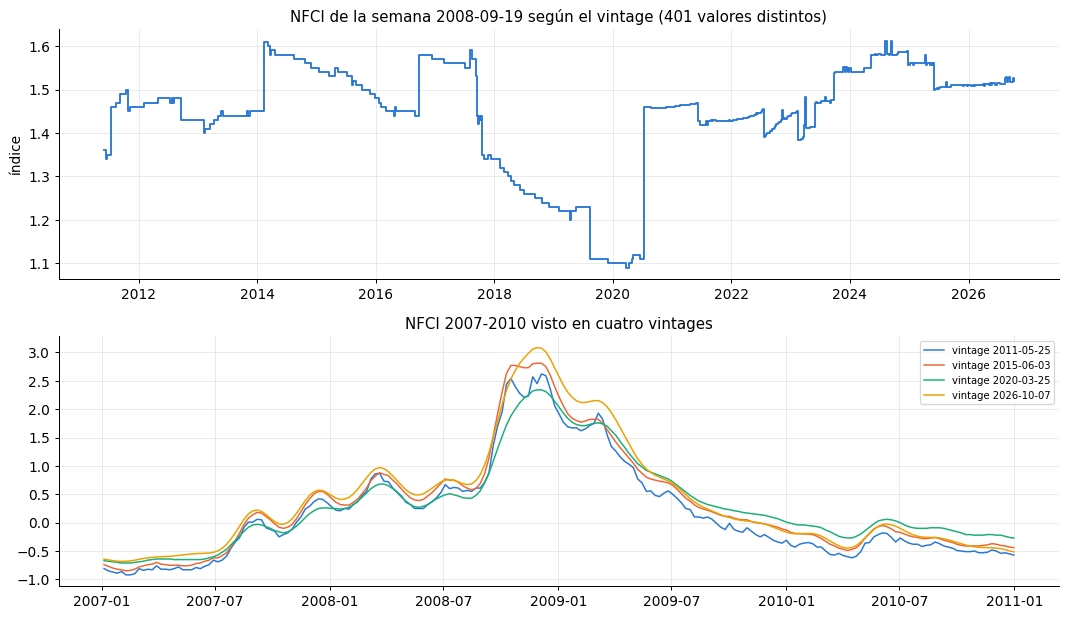

2801 vintages, 928,189 filas en la base; rango del valor de esa semana entre vintages: 0.52 desviaciones típicas
Aviso de get_serie: ['índice re-estimado entero en cada publicación: los 2568 periodos son los del vintage vigente en la fecha (último vintage visible: 2020-03-25); en otra fecha cambian también los valores antiguos']


In [8]:
nf = almacen.leer_series('fred:NFCI')
semana = pd.Timestamp('2008-09-19')
s = nf[(nf['fecha_referencia'] == semana) & (nf['metodo_publicacion'] == 'vintage_exacto')].sort_values('fecha_publicacion')
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].step(pd.to_datetime(s['vintage']), s['valor'], where='post', color='#2a78d6')
axes[0].set_title(f'NFCI de la semana {semana.date()} según el vintage ({len(s)} valores distintos)')
axes[0].set_ylabel('índice')
for i, v in enumerate(['2011-05-25', '2015-06-03', '2020-03-25', nf['vintage'].max()]):
    vista = alfred.vista_vintage(nf, 'fred:NFCI', v)
    vista = vista['2007-01-01':'2010-12-31']
    axes[1].plot(vista.index, vista.values, lw=1.2, color=PALETA[i], label=f'vintage {v}')
axes[1].set_title('NFCI 2007-2010 visto en cuatro vintages')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
n = tools.get_serie('NFCI', '2020-03-25')
print(f'{nf["vintage"].nunique()} vintages, {len(nf):,} filas en la base; rango del valor de esa semana entre vintages: '
      f'{s["valor"].max() - s["valor"].min():.2f} desviaciones típicas')
print('Aviso de get_serie:', [a for a in n.avisos if 're-estimado' in a])

## 8. Ediciones académicas

Ken French, Shiller y Goyal-Welch no están en ALFRED: su historia de revisiones es el **archivo propio de
ediciones** (vintage `AAAA-MM`): la copia de `data/raw` de la Fase 1 y las descargas del bloque 2. Cada barra
cuenta, por serie y edición, los valores revisados y los periodos nuevos respecto a la edición anterior
(`tablas/academicos_ediciones.csv`, sin valores).

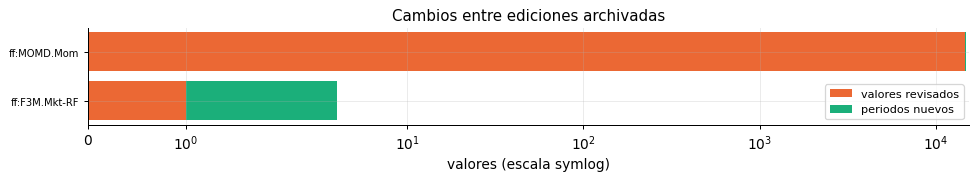

goyal_welch: 23,644 valores comunes, 0 revisados (0.0 %), 0 nuevos, 0 retirados
ken_french: 27,351 valores comunes, 14,700 revisados (53.7 %), 67 nuevos, 0 retirados


Aviso de get_serie (momentum diario): ['valores por edición del fichero (vintage AAAA-MM): 26216 periodos de 2 ediciones (2026-07, 2026-09); la última visible en la fecha es 2026-09; 11453 periodos con el valor de la primera edición archivada: posible fuga de revisiones anteriores a ella']


In [9]:
ed = pd.read_csv(TABLAS / 'academicos_ediciones.csv')
ed = ed[ed['etiqueta'] != ed['previa']] if 'previa' in ed else ed
agg = ed.groupby(['fuente', 'id'])[['comunes', 'revisados', 'nuevos']].sum()
agg = agg[(agg['revisados'] + agg['nuevos']) > 0].sort_values('revisados')
fig, ax = plt.subplots(figsize=(11, 0.32 * len(agg) + 1.5))
y = np.arange(len(agg))
ax.barh(y, agg['revisados'], color='#eb6834', label='valores revisados')
ax.barh(y, agg['nuevos'], left=agg['revisados'], color='#1baf7a', label='periodos nuevos')
ax.set_yticks(y)
ax.set_yticklabels(agg.index.get_level_values('id'), fontsize=8)
ax.set_xscale('symlog')
ax.set_xlabel('valores (escala symlog)')
ax.set_title('Cambios entre ediciones archivadas')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
por_fuente = ed.groupby('fuente')[['comunes', 'revisados', 'nuevos', 'retirados']].sum()
for f, r in por_fuente.iterrows():
    print(f'{f}: {int(r.comunes):,} valores comunes, {int(r.revisados):,} revisados '
          f'({100 * r.revisados / max(r.comunes, 1):.1f} %), {int(r.nuevos):,} nuevos, {int(r.retirados)} retirados')
m = tools.get_serie('ff:MOMD.Mom', '2026-10-13')
print('Aviso de get_serie (momentum diario):', [a for a in m.avisos if 'edición' in a])

## 9. Conclusiones

- **Cobertura.** Las 161 series de la lista están en la base con todas sus vintages de ALFRED: 7,19 millones de
  filas, unas 135 000 vintages y 74 621 filas anteriores a ALFRED (156 series con regla previa). La mitad de las
  series solo tiene vintages desde los años 2010: para ellas, casi toda la historia es «anterior a ALFRED» (valor del
  primer vintage con la fecha de la regla), y `get_serie` lo avisa.
- **Las revisiones importan.** En la serie mediana se revisa el 99 % de los periodos. El empleo de 2008 se publicó
  como una pérdida de unos 1,9 millones de empleos y hoy son unos 3,5 millones: con el último vintage, un agente en
  2008 habría «sabido» que la crisis era el doble de profunda. Precios y empleo se revisan poco en nivel (mediana
  0,2 % y 0,9 %); los agregados del PIB, el comercio exterior, el crédito y los índices de estrés, mucho más.
- **Fechas reales.** Los vintages recogen los retrasos que ninguna regla fija ve: el empleo de septiembre de 2013 se
  publicó el 2013-10-22 y el de septiembre de 2025 el 2025-11-20; el IPC de octubre de 2025 no existe (hueco con
  aviso). Con la regla del bloque 2 se adelantaba la fecha del 2,8 % de los periodos medidos (128 de 156 series,
  hasta 144 días; sin contar los rellenos de historia); con los vintages exactos, ninguno.
- **Índices re-estimados.** El NFCI cambia toda su historia cada semana: la semana de Lehman ha tenido 401 valores
  distintos en un rango de 0,5 desviaciones típicas. La respuesta de `get_serie` depende de la fecha de consulta
  también en los valores antiguos (aviso «re-estimado entero»).
- **Académicas.** Entre ediciones, Ken French revisó el 54 % de los valores comunes (momentum diario); Shiller y
  Goyal-Welch no cambiaron. Su primera edición archivada sigue teniendo posible fuga de revisiones anteriores.
- **Límites.** Las series con unidad por vintage mezclan años base entre vintages (los niveles de vintages distintos
  no se comparan); los rellenos de historia de ALFRED (USREC 1854-1920, PPI o Z.1 antiguos) se ven desde el vintage
  que los añadió, lo que es conservador; las proyecciones del SEP solo se ven desde su año.